In [1]:
# --------------------------------------------------------------------------
# 0. Libraries and Reproducibility
# --------------------------------------------------------------------------
import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm, skew, qmc
from scipy.optimize import minimize
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel
from sklearn.exceptions import ConvergenceWarning

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(SEED)
np.set_printoptions(precision=6, suppress=True)


print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [ ]:
# --------------------------------------------------------------------------
# Data  
# --------------------------------------------------------------------------
X = np.load('..\Function_3_Data\Week_10_Data/F3_Week_10_inputs.npy')
y = np.load('..\Function_3_Data\Week_10_Data/F3_Week_10_outputs.npy')
n, d = X.shape
PREVIOUS_N = 23          # dataset size as of v2 -- used only to label "new" points
N_NEW = n - PREVIOUS_N
N_INITIAL = 15           # REV R4: rows 0-14 are the initial design, the rest were queried
print(f"n = {n} observations ({N_INITIAL} initial + {n - N_INITIAL} queried), "
      f"d = {d} input dimensions ({N_NEW} new vs. the last run)")

BOUNDS = np.array([[0.0, 1.0]] * d)

n = 24 observations (15 initial + 9 queried), d = 3 input dimensions (1 new vs. the last run)


In [4]:
# --------------------------------------------------------------------------
# Last Week's query
# --------------------------------------------------------------------------
prev_incumbent_x = np.array([0.459956, 0.570861, 0.426532])   # best after n=23
prev_incumbent_y = -0.008172
prev_recommended_x = np.array([0.481200, 0.559200, 0.424900])  # v2's EI argmax

new_x, new_y = X[-1], y[-1]
print(f"Last week's query evaluated at: {np.round(new_x, 6)}")
print(f"Resulted at: y = {new_y:.6f}")
print(f"previous incumbent: y = {prev_incumbent_y:.6f} at "
      f"{np.round(prev_incumbent_x, 6)}")

best_idx = int(np.argmax(y))
x_best, y_best = X[best_idx], y[best_idx]
print(f"\nCurrent incumbent (best observed over all {n} points): "
      f"x*={np.round(x_best, 6)}, y*={y_best:.6f}  (row index {best_idx})")


Last week's query evaluated at: [0.48116  0.55917  0.424929]
Resulted at: y = -0.011447
previous incumbent: y = -0.008172 at [0.459956 0.570861 0.426532]

Current incumbent (best observed over all 24 points): x*=[0.459956 0.570861 0.426532], y*=-0.008172  (row index 21)


Transform check on all points, 6-decimal precision
raw y    : min=-0.398926 max=-0.008172 mean=-0.078374 std=0.078982 skew=-2.644841
g=-log(-y): min=0.918981 max=4.807087 mean=2.982666 std=0.983498 skew=0.192224
dynamic range compression: max(|y|)/min(|y|) = 48.818356x  ->  g range = 3.888106


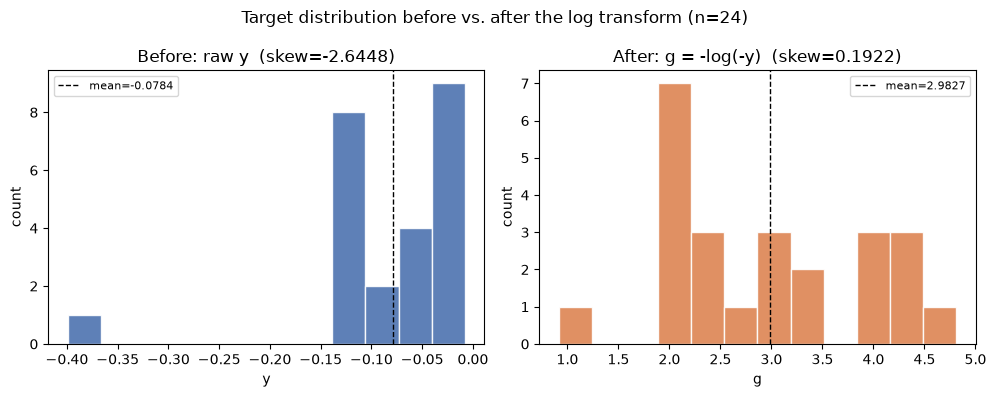

In [5]:
# --------------------------------------------------------------------------
# Output transformation + BEFORE/AFTER distribution plot
# --------------------------------------------------------------------------
# y is still strictly negative with one severe outlier (-0.398926) far from
# the rest (everything else sits in roughly [-0.13, -0.008]), so
# g(x) = -log(-y(x)) still applies.
g = -np.log(-y)
g_best = g[best_idx]

print("=" * 100)
print("Transform check on all points, 6-decimal precision")
print("=" * 100)

print(f"raw y    : min={y.min():.6f} max={y.max():.6f} mean={y.mean():.6f} "
      f"std={y.std():.6f} skew={skew(y):.6f}")
print(f"g=-log(-y): min={g.min():.6f} max={g.max():.6f} mean={g.mean():.6f} "
      f"std={g.std():.6f} skew={skew(g):.6f}")
print(f"dynamic range compression: max(|y|)/min(|y|) = "
      f"{np.abs(y).max()/np.abs(y).min():.6f}x  ->  "
      f"g range = {g.max()-g.min():.6f}")

# Plot: target distribution BEFORE vs AFTER transformation (requested #2)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(y, bins=12, color="#4C72B0", edgecolor="white", alpha=0.9)
axes[0].axvline(y.mean(), color="black", ls="--", lw=1, label=f"mean={y.mean():.4f}")
axes[0].set_title(f"Before: raw y  (skew={skew(y):.4f})")
axes[0].set_xlabel("y")
axes[0].set_ylabel("count")
axes[0].legend(fontsize=8)

axes[1].hist(g, bins=12, color="#DD8452", edgecolor="white", alpha=0.9)
axes[1].axvline(g.mean(), color="black", ls="--", lw=1, label=f"mean={g.mean():.4f}")
axes[1].set_title(f"After: g = -log(-y)  (skew={skew(g):.4f})")
axes[1].set_xlabel("g")
axes[1].set_ylabel("count")
axes[1].legend(fontsize=8)

fig.suptitle("Target distribution before vs. after the log transform (n=24)")
fig.tight_layout()



In [ ]:
# --------------------------------------------------------------------------
# Surrogate model: Gaussian Process
# --------------------------------------------------------------------------
# Kernel family unchanged: Matern(nu=2.5) x ConstantKernel + WhiteKernel.
# We keep the noise_level_bounds upper edge at 3e-1.

def make_gp(ard: bool, n_dims: int, seed: int) -> GaussianProcessRegressor:
    length_scale = np.ones(n_dims) if ard else 1.0
    kernel = (
        ConstantKernel(1.0, (1e-2, 1e2))
        * Matern(length_scale=length_scale, length_scale_bounds=(1e-2, 1e2), nu=2.5)
        + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-8, 3e-1))
    )
    return GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,
        n_restarts_optimizer=20,
        random_state=seed,
    )

def loo_cv(ard: bool, X, g, seed):
    n = len(g)
    sq_err = np.zeros(n)
    nlpd = np.zeros(n)
    for i in range(n):
        mask = np.ones(n, dtype=bool)
        mask[i] = False
        gp = make_gp(ard, X.shape[1], seed)
        gp.fit(X[mask], g[mask])
        mu, std = gp.predict(X[i:i+1], return_std=True)
        mu, std = mu[0], max(std[0], 1e-6)
        sq_err[i] = (mu - g[i]) ** 2
        nlpd[i] = 0.5 * np.log(2 * np.pi * std**2) + 0.5 * ((g[i] - mu) ** 2) / std**2
    return np.sqrt(sq_err.mean()), nlpd.mean()

print("=" * 100)
print("Model selection RE-RUN on all points: isotropic vs ARD (leave-one-out CV)")
print("=" * 100)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", category=ConvergenceWarning)
    results = {}
    for ard in (False, True):
        rmse, nlpd = loo_cv(ard, X, g, SEED)
        gp_full = make_gp(ard, d, SEED).fit(X, g)
        lml = gp_full.log_marginal_likelihood(gp_full.kernel_.theta)
        results[ard] = (rmse, nlpd, lml, gp_full)
        tag = "ARD      " if ard else "Isotropic"
        print(f"{tag}: LOO-RMSE(g)={rmse:.6f}  LOO-NLPD={nlpd:.6f}  train LML={lml:.6f}")
        print(f"           fitted kernel: {gp_full.kernel_}")
    n_conv_warnings = sum(1 for w in caught if issubclass(w.category, ConvergenceWarning))


use_ard = results[True][1] < results[False][1]
print(f"\n=> Selected model: {'ARD' if use_ard else 'Isotropic'} "
      "(lower leave-one-out NLPD; RMSE used as a tie-breaker)")


gp = results[use_ard][3]
print("\nFitted hyperparameters of the chosen GP:")
print(gp.kernel_)
fitted_ls = gp.kernel_.get_params()["k1__k2__length_scale"]
fitted_noise = gp.kernel_.get_params()["k2__noise_level"]
print(f"  length_scale = {np.atleast_1d(fitted_ls).round(6)}")
print(f"  noise_level  = {fitted_noise:.6f}")

LS_BOUNDS = (1e-2, 1e2)
def report_bounds(gp_model, tag):
    ls = np.atleast_1d(gp_model.kernel_.get_params()["k1__k2__length_scale"])
    for j, v in enumerate(ls):
        for b, side in zip(LS_BOUNDS, ("LOWER", "UPPER")):
            if np.isclose(v, b, rtol=1e-3):
                name = f"x{j+1} length scale" if len(ls) > 1 else "length scale"
                print(f"  WARNING [{tag}]: {name} ({v:.6f}) is on its {side} bound")

print("\nBound check:")
report_bounds(results[False][3], "Isotropic")
report_bounds(results[True][3], "ARD")

def incumbent(gp_model):
    """Best posterior mean at an observed point: (row index, value in g)."""
    mu_train = gp_model.predict(X)
    return int(np.argmax(mu_train)), float(mu_train.max())
inc_idx, g_inc = incumbent(gp)


Model selection RE-RUN on all points: isotropic vs ARD (leave-one-out CV)
Isotropic: LOO-RMSE(g)=0.730819  LOO-NLPD=1.146814  train LML=-24.374522
           fitted kernel: 0.823**2 * Matern(length_scale=0.0905, nu=2.5) + WhiteKernel(noise_level=0.0103)
ARD      : LOO-RMSE(g)=0.620556  LOO-NLPD=2.537394  train LML=-19.396878
           fitted kernel: 1**2 * Matern(length_scale=[100, 0.688, 0.0993], nu=2.5) + WhiteKernel(noise_level=0.0382)

=> Selected model: Isotropic (lower leave-one-out NLPD; RMSE used as a tie-breaker)

Fitted hyperparameters of the chosen GP:
0.823**2 * Matern(length_scale=0.0905, nu=2.5) + WhiteKernel(noise_level=0.0103)
  length_scale = [0.090549]
  noise_level  = 0.010339

Bound check:
  WARNING [ARD]: x1 length scale (100.000000) is on its UPPER bound


In [ ]:
# --------------------------------------------------------------------------
# 5. Acquisition function: Expected Improvement, re-tuned for EXPLOITATION
# --------------------------------------------------------------------------

def latent_posterior(Xcand, gp_model):
    """Posterior mean and std of the LATENT function (WhiteKernel variance
    removed -- sklearn's predict() std is for a new noisy observation)."""
    mu, sigma = gp_model.predict(Xcand, return_std=True)
    noise_var = gp_model.kernel_.get_params()["k2__noise_level"] * gp_model._y_train_std ** 2
    return mu, np.sqrt(np.maximum(sigma ** 2 - noise_var, 1e-18))

XI = 0.01
def expected_improvement(Xcand, gp, g_best, xi=XI):
    # REV R3: latent std; g_best should be the posterior-mean incumbent.
    # mu, sigma = gp.predict(Xcand, return_std=True)
    mu, sigma = latent_posterior(Xcand, gp)
    z = (mu - g_best - xi) / sigma
    return (mu - g_best - xi) * norm.cdf(z) + sigma * norm.pdf(z)

In [ ]:
# --------------------------------------------------------------------------
# 6. Optimising the acquisition function -> next query point
# --------------------------------------------------------------------------
def propose_next(gp, g_best, bounds, xi, n_restarts=20, n_sobol=2**15, seed=SEED):
    dim = bounds.shape[0]
    sobol = qmc.Sobol(dim, seed=seed).random(n_sobol)
    cands = np.vstack([bounds[:, 0] + sobol * (bounds[:, 1] - bounds[:, 0]), X])
    ei_cands = expected_improvement(cands, gp, g_best, xi=xi)
    order = np.argsort(-ei_cands)[:n_restarts]
    best_x, best_val = cands[order[0]], ei_cands[order[0]]

    def neg_ei(x):
        return -expected_improvement(x.reshape(1, -1), gp, g_best, xi=xi)[0]

    for x0 in cands[order]:
        res = minimize(neg_ei, x0, bounds=bounds, method="L-BFGS-B")
        if -res.fun > best_val:
            best_val, best_x = -res.fun, res.x
    return best_x, best_val

# inc_idx, g_inc = incumbent(gp)
x_next, ei_next = propose_next(gp, g_inc, BOUNDS, xi=XI)
mu_next, std_next = latent_posterior(x_next.reshape(1, -1), gp)

print("=" * 100)
print("Next recommended query point")
print("=" * 100)

print(f"x_next = {np.round(x_next, 6)}")
print(f"EI(x_next) = {ei_next:.6f}   posterior mean g = {mu_next[0]:.6f} "
      f"+/- {std_next[0]:.6f}")

Next recommended query point
x_next = [0.44653  0.572743 0.423725]
EI(x_next) = 0.052293   posterior mean g = 4.726751 +/- 0.129260


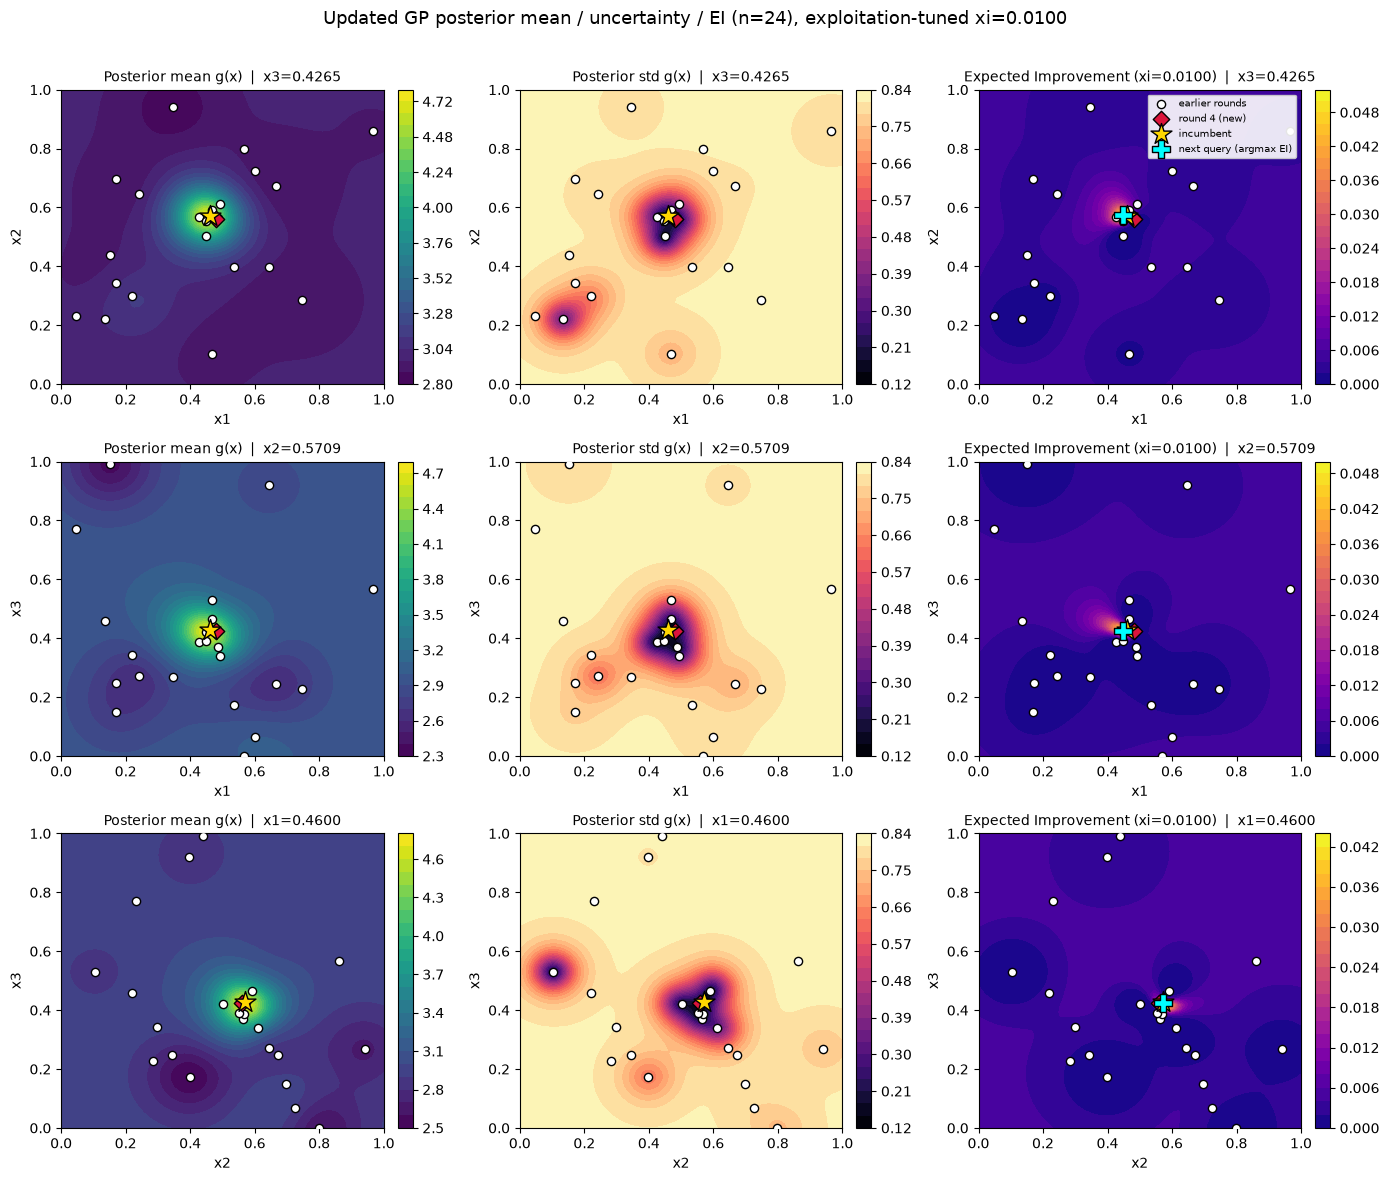

In [9]:
# --------------------------------------------------------------------------
# 7. Diagnostic / explanatory plots
# --------------------------------------------------------------------------
grid_n = 80
lin = np.linspace(0, 1, grid_n)
dim_names = ["x1", "x2", "x3"]
pairs = [(0, 1), (0, 2), (1, 2)]

fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for row, (i, j) in enumerate(pairs):
    k = [a for a in range(3) if a not in (i, j)][0]
    fixed_val = x_best[k]

    A, B = np.meshgrid(lin, lin)
    grid = np.zeros((grid_n * grid_n, 3))
    grid[:, i] = A.ravel()
    grid[:, j] = B.ravel()
    grid[:, k] = fixed_val

    mu, std = gp.predict(grid, return_std=True)
    ei = expected_improvement(grid, gp, g_inc)

    mu_grid = mu.reshape(grid_n, grid_n)
    std_grid = std.reshape(grid_n, grid_n)
    ei_grid = ei.reshape(grid_n, grid_n)

    for col, (Z, title, cmap) in enumerate([
        (mu_grid, f"Posterior mean g(x)  |  {dim_names[k]}={fixed_val:.4f}", "viridis"),
        (std_grid, f"Posterior std g(x)  |  {dim_names[k]}={fixed_val:.4f}", "magma"),
        (ei_grid, f"Expected Improvement (xi={XI:.4f})  |  {dim_names[k]}={fixed_val:.4f}", "plasma"),
    ]):
        ax = axes[row, col]
        cf = ax.contourf(A, B, Z, levels=25, cmap=cmap)
        fig.colorbar(cf, ax=ax, fraction=0.046, pad=0.04)
        ax.scatter(X[:-N_NEW, i], X[:-N_NEW, j], c="white", edgecolor="black", s=35,
                   zorder=3, label="earlier rounds")
        ax.scatter(X[-N_NEW:, i], X[-N_NEW:, j], c="crimson", edgecolor="black", s=70,
                   marker="D", zorder=4, label="round 4 (new)")
        ax.scatter(x_best[i], x_best[j], marker="*", c="gold", s=250,
                   edgecolor="black", zorder=5, label="incumbent")
        if col == 2:
            ax.scatter(x_next[i], x_next[j], marker="P", c="cyan", s=180,
                       edgecolor="black", zorder=5, label="next query (argmax EI)")
        ax.set_xlabel(dim_names[i])
        ax.set_ylabel(dim_names[j])
        ax.set_title(title, fontsize=10)
        if row == 0 and col == 2:
            ax.legend(loc="upper right", fontsize=7, framealpha=0.9)

fig.suptitle(f"Updated GP posterior mean / uncertainty / EI (n={n}), exploitation-tuned xi={XI:.4f}",
             fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.97])

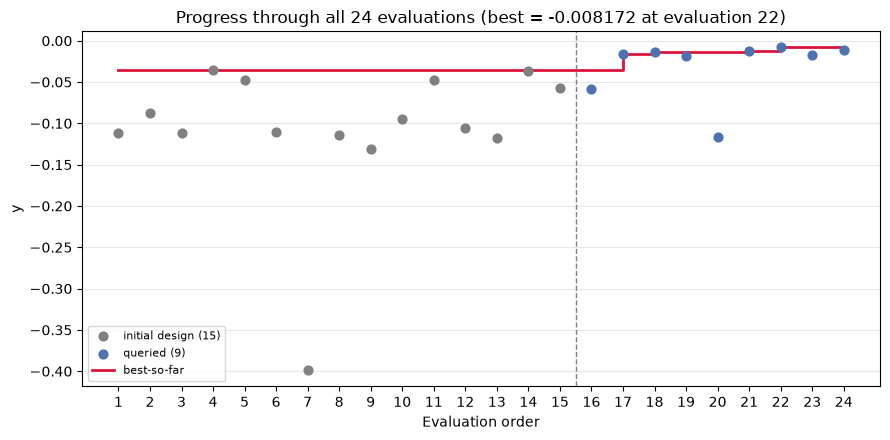

In [ ]:
# Progress through the rounds
fig, ax = plt.subplots(figsize=(9, 4.5))
evals = np.arange(1, n + 1)
running_best = np.maximum.accumulate(np.r_[np.full(N_INITIAL, y[:N_INITIAL].max()), y[N_INITIAL:]])
ax.scatter(evals[:N_INITIAL], y[:N_INITIAL], c="gray", s=40, zorder=3, label=f"initial design ({N_INITIAL})")
ax.scatter(evals[N_INITIAL:], y[N_INITIAL:], c="#4C72B0", s=40, zorder=3, label=f"queried ({n - N_INITIAL})")
ax.step(evals, running_best, where="post", lw=2, color="crimson", zorder=2, label="best-so-far")
ax.axvline(N_INITIAL + 0.5, color="gray", ls="--", lw=1)
ax.set_xticks(evals)
ax.set_xlabel("Evaluation order")
ax.set_ylabel("y")
ax.set_title(f"Progress through all {n} evaluations (best = {y_best:.6f} at evaluation {best_idx + 1})")
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()